In [15]:
import os
import re
import numpy as np
from PIL import Image
import pydicom
from pydicom.dataset import FileDataset
from pydicom.uid import generate_uid
from datetime import datetime

# ----------------------------
# CONFIG
# ----------------------------
RESULTS_DIR = "/HPC/fnu.talha/resvit/results/T1_T2_Flair_T1ce_nc_3_FullBrats2021_WeightedL1_ErrorMap_RDEB_GradientLoss_batch_24_ResVit/test_latest/images"
OUTPUT_DIR = "/HPC/fnu.talha/resvit/results/T1_T2_Flair_T1ce_nc_3_FullBrats2021_WeightedL1_ErrorMap_RDEB_GradientLoss_batch_24_ResVit/test_latest/"

CASE_ID = "BraTS2021_00819"
MODALITY = "T1ce"
SLICE_START = 40
SLICE_END = 114

PIXEL_SPACING = [1.0, 1.0]   # mm
SLICE_THICKNESS = 1.0        # mm

# ----------------------------
# Create output dirs
# ----------------------------
real_out = os.path.join(OUTPUT_DIR, CASE_ID, "real_T1ce")
pred_out = os.path.join(OUTPUT_DIR, CASE_ID, "pred_T1ce")
os.makedirs(real_out, exist_ok=True)
os.makedirs(pred_out, exist_ok=True)

# ----------------------------
# Create UIDs
# ----------------------------
study_uid = generate_uid()
real_series_uid = generate_uid()
pred_series_uid = generate_uid()

# ----------------------------
# Filename pattern
# ----------------------------
pattern = re.compile(
    rf"({CASE_ID})_slice_(\d+)_(real|Pred)_{MODALITY}\.png"
)

# ----------------------------
# Collect matching files
# ----------------------------
files = []
for f in os.listdir(RESULTS_DIR):
    m = pattern.match(f)
    if m:
        slice_idx = int(m.group(2))
        if SLICE_START <= slice_idx <= SLICE_END:
            files.append((slice_idx, m.group(3), f))

# Sort by slice index
files.sort(key=lambda x: x[0])

# ----------------------------
# DICOM writer
# ----------------------------
from pydicom.uid import (
    ExplicitVRLittleEndian,
    SecondaryCaptureImageStorage
)

def write_dicom(png_path, out_path, instance_number,
                series_uid, slice_index):

    img = Image.open(png_path).convert("L")
    pixel_array = np.array(img).astype(np.uint16)

    # ---- File Meta ----
    file_meta = pydicom.Dataset()
    file_meta.MediaStorageSOPClassUID = SecondaryCaptureImageStorage
    file_meta.MediaStorageSOPInstanceUID = generate_uid()
    file_meta.TransferSyntaxUID = ExplicitVRLittleEndian
    file_meta.ImplementationClassUID = generate_uid()

    ds = FileDataset(
        out_path,
        {},
        file_meta=file_meta,
        preamble=b"\0" * 128
    )

    # ---- REQUIRED encoding flags ----
    ds.is_little_endian = True
    ds.is_implicit_VR = False

    # ---- Patient / Study ----
    ds.PatientName = CASE_ID
    ds.PatientID = CASE_ID
    ds.StudyInstanceUID = study_uid
    ds.SeriesInstanceUID = series_uid
    ds.StudyDate = datetime.now().strftime("%Y%m%d")
    ds.Modality = "MR"

    # ---- Image Geometry ----
    ds.Rows, ds.Columns = pixel_array.shape
    ds.InstanceNumber = instance_number
    ds.ImagePositionPatient = [0.0, 0.0, slice_index * SLICE_THICKNESS]
    ds.ImageOrientationPatient = [1, 0, 0, 0, 1, 0]
    ds.PixelSpacing = PIXEL_SPACING
    ds.SliceThickness = SLICE_THICKNESS

    # ---- Pixel Data ----
    ds.SamplesPerPixel = 1
    ds.PhotometricInterpretation = "MONOCHROME2"
    ds.BitsAllocated = 16
    ds.BitsStored = 16
    ds.HighBit = 15
    ds.PixelRepresentation = 0
    ds.PixelData = pixel_array.tobytes()

    # ---- Save correctly ----
    ds.save_as(out_path, write_like_original=False)

# ----------------------------
# Convert files
# ----------------------------


for slice_idx, kind, fname in files:
    png_path = os.path.join(RESULTS_DIR, fname)

    instance_number = slice_idx  # <-- KEY CHANGE
    z_pos = (slice_idx - SLICE_START) * SLICE_THICKNESS

    if kind == "real":
        out_file = os.path.join(real_out, f"IM_{slice_idx:04d}.dcm")
        write_dicom(
            png_path,
            out_file,
            instance_number,
            real_series_uid,
            z_pos
        )

    else:  # Pred
        out_file = os.path.join(pred_out, f"IM_{slice_idx:04d}.dcm")
        write_dicom(
            png_path,
            out_file,
            instance_number,
            pred_series_uid,
            z_pos
        )


print("✅ DICOM conversion complete for", CASE_ID)


✅ DICOM conversion complete for BraTS2021_00819


In [ ]:
import os
import pydicom
import numpy as np
import matplotlib.pyplot as plt

def load_dicom_series(folder):
    files = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.endswith(".dcm")
    ]

    # Read metadata only
    datasets = [pydicom.dcmread(f, stop_before_pixels=True, force=True)
                for f in files]

    # Sort by InstanceNumber
    datasets.sort(key=lambda d: int(d.InstanceNumber))

    # Read first slice fully to get shape
    first = pydicom.dcmread(files[0], force=True)
    vol = np.zeros((len(datasets),
                    first.Rows,
                    first.Columns),
                   dtype=first.pixel_array.dtype)

    # Load pixel data slice-by-slice
    for i, ds in enumerate(datasets):
        ds_full = pydicom.dcmread(ds.filename, force=True)
        vol[i] = ds_full.pixel_array

    return vol



real_dir = "/HPC/fnu.talha/resvit/results/T1_T2_Flair_T1ce_nc_3_FullBrats2021_WeightedL1_ErrorMap_RDEB_GradientLoss_batch_24_ResVit/test_latest/BraTS2021_00819/real_T1ce"
pred_dir = "/HPC/fnu.talha/resvit/results/T1_T2_Flair_T1ce_nc_3_FullBrats2021_WeightedL1_ErrorMap_RDEB_GradientLoss_batch_24_ResVit/test_latest/BraTS2021_00819/pred_T1ce"


real_vol = load_dicom_series(real_dir)
pred_vol = load_dicom_series(pred_dir)

print(real_vol.shape, pred_vol.shape)


from ipywidgets import interact, IntSlider

def view_slice(idx):
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(real_vol[idx], cmap="gray")
    plt.title("REAL T1ce")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(pred_vol[idx], cmap="gray")
    plt.title("PRED T1ce")
    plt.axis("off")

    plt.show()

interact(view_slice,
         idx=IntSlider(min=0, max=real_vol.shape[0]-1, step=1, value=0))


(75, 256, 256) (75, 256, 256)


interactive(children=(IntSlider(value=0, description='idx', max=74), Output()), _dom_classes=('widget-interact…

<function __main__.view_slice(idx)>

In [ ]:
import re

def extract_metrics(file_path):
    psnr = []
    ssim = []

    with open(file_path, 'r') as f:
        for line in f:
            match = re.search(r'PSNR:\s*([0-9.]+),\s*SSIM:\s*([0-9.]+)', line)
            if match:
                psnr.append(float(match.group(1)))
                ssim.append(float(match.group(2)))

    return psnr, ssim


# Example usage
aavit_psnr, aavit_ssim = extract_metrics("resvit_2487.out")
fft_psnr, fft_ssim = extract_metrics("fft.out")

print("Total images:", len(aavit_ssim))
print("First 5 PSNR:", aavit_psnr[:5])



Total images: 22742
First 5 PSNR: [33.12866647876959, 33.433349848282376, 33.58520076887979, 33.967799942233164, 35.445829975998066]


In [3]:
import re
import numpy as np
from scipy.stats import wilcoxon

# --------------------------------------------------
# 1️⃣  Function to extract PSNR & SSIM from .out file
# --------------------------------------------------
def extract_metrics(file_path):
    psnr = []
    ssim = []

    with open(file_path, 'r') as f:
        for line in f:
            match = re.search(r'PSNR:\s*([0-9.]+),\s*SSIM:\s*([0-9.]+)', line)
            if match:
                psnr.append(float(match.group(1)))
                ssim.append(float(match.group(2)))

    return np.array(psnr), np.array(ssim)


# --------------------------------------------------
# 2️⃣  Define all experiments
# --------------------------------------------------
experiments = {
    "Baseline": "resvit_1399.out",
    "+ Error map": "resvit_2311.out",
    "+ Error map + RDEB + Gradient": "resvit_2325.out",
    "+ Error map + RDEB + Gradient + FFT": "resvit_2733.out"
}

# --------------------------------------------------
# 3️⃣  Load baseline
# --------------------------------------------------
baseline_psnr, baseline_ssim = extract_metrics(experiments["Baseline"])

results = []

# --------------------------------------------------
# 4️⃣  Process all experiments
# --------------------------------------------------
for name, file in experiments.items():

    psnr, ssim = extract_metrics(file)

    mean_psnr = np.mean(psnr)
    std_psnr = np.std(psnr)

    mean_ssim = np.mean(ssim)
    std_ssim = np.std(ssim)

    # Statistical significance vs baseline (skip baseline itself)
    if name != "Baseline":
        _, p_psnr = wilcoxon(psnr, baseline_psnr)
        _, p_ssim = wilcoxon(ssim, baseline_ssim)

        def significance(p):
            if p < 0.01:
                return "**"
            elif p < 0.05:
                return "*"
            else:
                return ""

        sig_psnr = significance(p_psnr)
        sig_ssim = significance(p_ssim)
    else:
        sig_psnr = ""
        sig_ssim = ""

    results.append({
        "name": name,
        "psnr": f"{mean_psnr:.3f} ± {std_psnr:.3f}{sig_psnr}",
        "ssim": f"{mean_ssim:.3f} ± {std_ssim:.3f}{sig_ssim}"
    })

# --------------------------------------------------
# 5️⃣  Print LaTeX table rows
# --------------------------------------------------
print("\nLaTeX Table Rows:\n")
for r in results:
    print(f"{r['name']} & ${r['psnr']}$ & ${r['ssim']}$ \\\\")


LaTeX Table Rows:

Baseline & $26.919 ± 4.657$ & $0.916 ± 0.040$ \\
+ Error map & $27.519 ± 4.655**$ & $0.926 ± 0.037**$ \\
+ Error map + RDEB + Gradient & $27.780 ± 4.866**$ & $0.929 ± 0.039**$ \\
+ Error map + RDEB + Gradient + FFT & $27.790 ± 4.927**$ & $0.930 ± 0.039**$ \\


In [5]:
import re
import numpy as np
from scipy.stats import wilcoxon

# --------------------------------------------------
# 1️⃣ Function to extract PSNR & SSIM from a .out file
# --------------------------------------------------
def extract_metrics(file_path):
    psnr, ssim = [], []
    with open(file_path, 'r') as f:
        for line in f:
            match = re.search(r'PSNR:\s*([0-9.]+),\s*SSIM:\s*([0-9.]+)', line)
            if match:
                psnr.append(float(match.group(1)))
                ssim.append(float(match.group(2)))
    return np.array(psnr), np.array(ssim)

# --------------------------------------------------
# 2️⃣ Define experiments
# --------------------------------------------------
experiments = {
    "Baseline": "resvit_1399.out",
    "+ Error map": "resvit_2311.out",
    "+ Error map + RDEB + Gradient": "resvit_2325.out",
    "+ Error map + RDEB + Gradient + FFT": "resvit_2733.out"
}

# --------------------------------------------------
# 3️⃣ Load baseline
# --------------------------------------------------
baseline_psnr, baseline_ssim = extract_metrics(experiments["Baseline"])

# --------------------------------------------------
# 4️⃣ Process experiments and compute significance stars
# --------------------------------------------------
results = []
for name, file in experiments.items():
    psnr, ssim = extract_metrics(file)
    
    mean_psnr = np.mean(psnr)
    std_psnr = np.std(psnr)
    mean_ssim = np.mean(ssim)
    std_ssim = np.std(ssim)

    if name != "Baseline":
        # Wilcoxon signed-rank test
        _, p_psnr = wilcoxon(psnr, baseline_psnr)
        _, p_ssim = wilcoxon(ssim, baseline_ssim)

        # Assign stars based on real p-values
        def stars(p):
            if p < 0.001:
                return "***"
            elif p < 0.01:
                return "**"
            elif p < 0.05:
                return "*"
            else:
                return ""

        sig_psnr = stars(p_psnr)
        sig_ssim = stars(p_ssim)
    else:
        sig_psnr = ""
        sig_ssim = ""

    results.append({
        "name": name,
        "psnr": f"{mean_psnr:.3f} ± {std_psnr:.3f}{sig_psnr}",
        "ssim": f"{mean_ssim:.3f} ± {std_ssim:.3f}{sig_ssim}"
    })

# --------------------------------------------------
# 5️⃣ Print LaTeX rows with actual significance stars
# --------------------------------------------------
print("\nLaTeX Table Rows:\n")
for r in results:
    print(f"{r['name']} & ${r['psnr']}$ & ${r['ssim']}$ \\\\")

    


LaTeX Table Rows:

Baseline & $26.919 ± 4.657$ & $0.916 ± 0.040$ \\
+ Error map & $27.519 ± 4.655***$ & $0.926 ± 0.037***$ \\
+ Error map + RDEB + Gradient & $27.780 ± 4.866***$ & $0.929 ± 0.039***$ \\
+ Error map + RDEB + Gradient + FFT & $27.790 ± 4.927***$ & $0.930 ± 0.039***$ \\


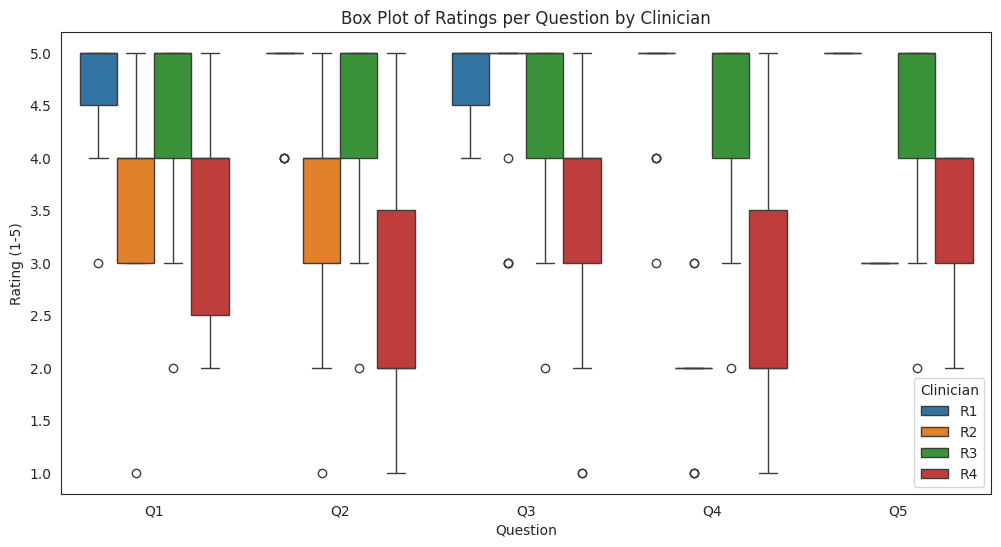

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -----------------------------
# Step 1: Create the data
# -----------------------------
# Example: ratings from 4 clinicians for 5 questions x 19 case studies
data = {
    "Clinician": [],
    "CaseStudy": [],
    "Question": [],
    "Rating": []
}

# Suppose you already have your raw ratings as lists
clinicians = ["R1", "R2", "R3", "R4"]

# Raw ratings per clinician (5 questions x 19 case studies)
ratings_raw = [
    # Peter Crossely
    [
        [4,5,4,5,5,5,3,5,4,5,5,5,5,5,5,5,5,4,5],
        [5,5,4,5,5,5,4,5,4,5,5,5,5,5,5,5,5,4,5],
        [4,5,4,5,5,5,4,5,4,5,5,5,5,5,5,5,5,4,5],
        [4,5,4,5,5,5,3,5,4,5,5,5,5,5,5,5,5,5,5],
        [5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5]
    ],
    # Matt Tenowed
    [
        [3,4,1,4,3,3,3,4,3,4,5,5,4,5,4,3,5,3,4],
        [4,4,1,4,3,4,3,4,3,4,5,5,4,5,3,3,5,2,4],
        [5,5,5,5,3,5,3,5,4,5,5,5,5,5,5,5,5,3,5],
        [2,2,1,2,3,2,3,2,1,2,2,2,2,2,2,2,2,1,2],
        [3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3]
    ],
    # Thomas Flannery
    [
        [4,5,3,5,5,5,4,5,5,5,5,2,5,5,4,4,5,4,5],
        [4,5,3,5,5,5,4,5,5,5,5,2,5,5,4,4,5,4,5],
        [4,5,3,5,5,5,4,5,5,5,5,2,5,5,4,4,5,4,5],
        [4,5,3,5,5,5,4,5,5,5,5,2,5,5,4,4,5,4,5],
        [5,5,3,5,5,5,4,5,5,5,5,2,5,5,4,4,5,4,5]
    ],
    # Charlie Cummins
    [
        [3,4,2,4,5,3,2,4,2,4,4,4,5,4,4,2,4,3,2],
        [2,4,2,2,2,3,2,4,2,3,2,3,4,4,2,2,5,1,2],
        [3,5,3,4,4,2,1,3,1,4,4,4,4,4,4,3,5,2,4],
        [2,4,2,4,3,2,2,4,2,5,1,2,3,2,2,1,4,1,2],
        [3,4,4,4,4,4,2,4,2,3,4,4,4,4,4,4,3,2,2]
    ]
]

# Convert to long format
for clinician_idx, clinician in enumerate(clinicians):
    clinician_ratings = ratings_raw[clinician_idx]
    for q_idx, question_ratings in enumerate(clinician_ratings):
        for cs_idx, rating in enumerate(question_ratings):
            data["Clinician"].append(clinician)
            data["Question"].append(f"Q{q_idx+1}")
            data["CaseStudy"].append(f"CS{cs_idx+1}")
            data["Rating"].append(rating)

df = pd.DataFrame(data)

# -----------------------------
# Step 2: Plot box plot
# -----------------------------
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x="Question", y="Rating", hue="Clinician")
plt.title("Box Plot of Ratings per Question by Clinician")
plt.ylabel("Rating (1-5)")
plt.xlabel("Question")
plt.legend(title="Clinician")
plt.show()

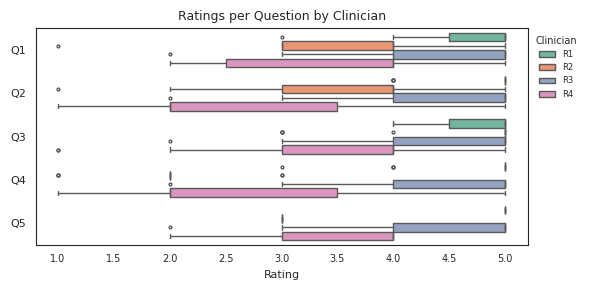

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assume 'df' already exists (long-format: Clinician, Question, CaseStudy, Rating)

# -----------------------------
# Compact publication-ready box plot
# -----------------------------
sns.set_style("white")  # clean style
plt.figure(figsize=(6,3))  # very compact figure

# Create horizontal boxes for compactness
sns.boxplot(
    data=df,
    y="Question",
    x="Rating",
    hue="Clinician",
    palette="Set2",
    fliersize=2,  # smaller outlier points
    linewidth=1
)

# Adjust font sizes for readability in small space
plt.title("Ratings per Question by Clinician", fontsize=9)
plt.xlabel("Rating", fontsize=8)
plt.ylabel("")  # drop ylabel for space
plt.xticks(fontsize=7)
plt.yticks(fontsize=8)

# Shrink legend and move slightly outside to avoid touching bars
plt.legend(
    title="Clinician",
    fontsize=6,
    title_fontsize=7,
    loc="upper left",
    bbox_to_anchor=(1,1),
    frameon=False
)

plt.tight_layout()  # removes extra white space

# -----------------------------
# Export high-resolution image
# -----------------------------
plt.savefig("ratings_boxplot.png", dpi=300, bbox_inches='tight')  # 300 dpi for publication
plt.show()

In [19]:
import pandas as pd

# Assume df already exists with columns: Clinician, Question, CaseStudy, Rating

# -----------------------------
# Calculate summary statistics per Clinician and Question
# -----------------------------
summary = df.groupby(["Clinician", "Question"]).Rating.agg(
    Mean='mean',
    SD='std',
    Median='median',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75),
    Min='min',
    Max='max'
).reset_index()

# Calculate IQR
summary['IQR'] = summary['Q3'] - summary['Q1']

# Round values for readability
summary = summary.round(2)

print(summary)

   Clinician Question  Mean    SD  Median   Q1   Q3  Min  Max  IQR
0         R1       Q1  4.68  0.58     5.0  4.5  5.0    3    5  0.5
1         R1       Q2  4.79  0.42     5.0  5.0  5.0    4    5  0.0
2         R1       Q3  4.74  0.45     5.0  4.5  5.0    4    5  0.5
3         R1       Q4  4.74  0.56     5.0  5.0  5.0    3    5  0.0
4         R1       Q5  5.00  0.00     5.0  5.0  5.0    5    5  0.0
5         R2       Q1  3.68  1.00     4.0  3.0  4.0    1    5  1.0
6         R2       Q2  3.68  1.06     4.0  3.0  4.0    1    5  1.0
7         R2       Q3  4.63  0.76     5.0  5.0  5.0    3    5  0.0
8         R2       Q4  1.95  0.52     2.0  2.0  2.0    1    3  0.0
9         R2       Q5  3.00  0.00     3.0  3.0  3.0    3    3  0.0
10        R3       Q1  4.47  0.84     5.0  4.0  5.0    2    5  1.0
11        R3       Q2  4.47  0.84     5.0  4.0  5.0    2    5  1.0
12        R3       Q3  4.47  0.84     5.0  4.0  5.0    2    5  1.0
13        R3       Q4  4.47  0.84     5.0  4.0  5.0    2    5 

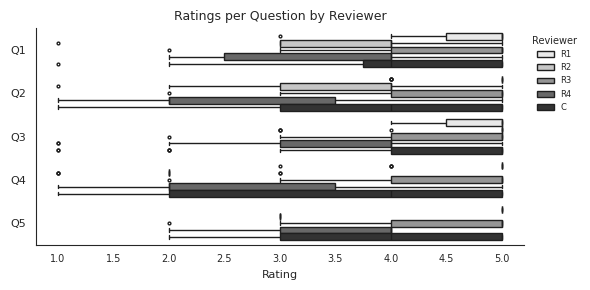

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# =====================================================
# ASSUMPTION:
# df exists in long format with columns:
# 'Clinician', 'Question', 'CaseStudy', 'Rating'
# =====================================================

# -----------------------------------------------------
# 1️⃣ Relabel reviewers (if needed)
# -----------------------------------------------------
clinician_map = {
    "Reviewer 1": "R1",
    "Reviewer 2": "R2",
    "Reviewer 3": "R3",
    "Reviewer 4": "R4"
}

df["Clinician"] = df["Clinician"].replace(clinician_map)

# -----------------------------------------------------
# 2️⃣ Create combined reviewer (C)
# -----------------------------------------------------
df_combined = df.copy()
df_combined["Clinician"] = "C"

df_plot = pd.concat([df, df_combined], ignore_index=True)

# -----------------------------------------------------
# 3️⃣ Fix reviewer order
# -----------------------------------------------------
reviewer_order = ["R1", "R2", "R3", "R4", "C"]

df_plot["Clinician"] = pd.Categorical(
    df_plot["Clinician"],
    categories=reviewer_order,
    ordered=True
)

# -----------------------------------------------------
# 4️⃣ Plot
# -----------------------------------------------------
sns.set_style("white")

plt.figure(figsize=(6, 3))

sns.boxplot(
    data=df_plot,
    y="Question",
    x="Rating",
    hue="Clinician",
    palette="Greys",      # grayscale-safe
    fliersize=2,
    linewidth=1
)

plt.title("Ratings per Question by Reviewer", fontsize=9)
plt.xlabel("Rating", fontsize=8)
plt.ylabel("")
plt.xticks(fontsize=7)
plt.yticks(fontsize=8)

# Compact, clean legend
plt.legend(
    title="Reviewer",
    fontsize=6,
    title_fontsize=7,
    loc="upper left",
    bbox_to_anchor=(1, 1),
    frameon=False
)

sns.despine()
plt.tight_layout()

plt.savefig("Figure4_revised_with_legend.png", dpi=300, bbox_inches="tight")
plt.show()

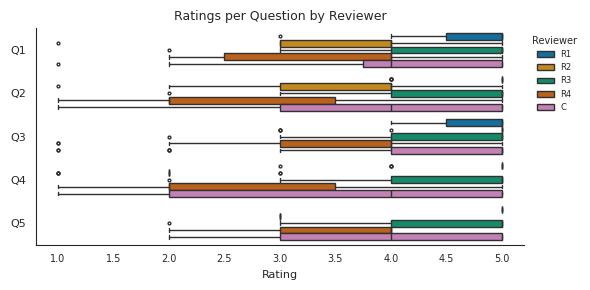

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# =====================================================
# ASSUMPTION:
# df exists in long format with columns:
# 'Clinician', 'Question', 'CaseStudy', 'Rating'
# =====================================================

# -----------------------------------------------------
# 1️⃣ Relabel reviewers (if needed)
# -----------------------------------------------------
clinician_map = {
    "Reviewer 1": "R1",
    "Reviewer 2": "R2",
    "Reviewer 3": "R3",
    "Reviewer 4": "R4"
}

df["Clinician"] = df["Clinician"].replace(clinician_map)

# -----------------------------------------------------
# 2️⃣ Create combined reviewer (C)
# -----------------------------------------------------
df_combined = df.copy()
df_combined["Clinician"] = "C"

df_plot = pd.concat([df, df_combined], ignore_index=True)

# -----------------------------------------------------
# 3️⃣ Fix reviewer order
# -----------------------------------------------------
reviewer_order = ["R1", "R2", "R3", "R4", "C"]

df_plot["Clinician"] = pd.Categorical(
    df_plot["Clinician"],
    categories=reviewer_order,
    ordered=True
)

# -----------------------------------------------------
# 4️⃣ Plot horizontal boxplots
# -----------------------------------------------------
sns.set_style("white")
plt.figure(figsize=(6, 3))  # your requested size

sns.boxplot(
    data=df_plot,
    y="Question",
    x="Rating",
    hue="Clinician",
    palette="colorblind",   # high-contrast, colour-safe
    fliersize=2,
    linewidth=1
)

plt.title("Ratings per Question by Reviewer", fontsize=9)
plt.xlabel("Rating", fontsize=8)
plt.ylabel("")
plt.xticks(fontsize=7)
plt.yticks(fontsize=8)

# Legend
plt.legend(
    title="Reviewer",
    fontsize=6,
    title_fontsize=7,
    loc="upper left",
    bbox_to_anchor=(1, 1),
    frameon=False
)

sns.despine()
plt.tight_layout()

# Save with dpi=300
plt.savefig("Figure4_revised_with_legend.png", dpi=300, bbox_inches="tight")
plt.show()

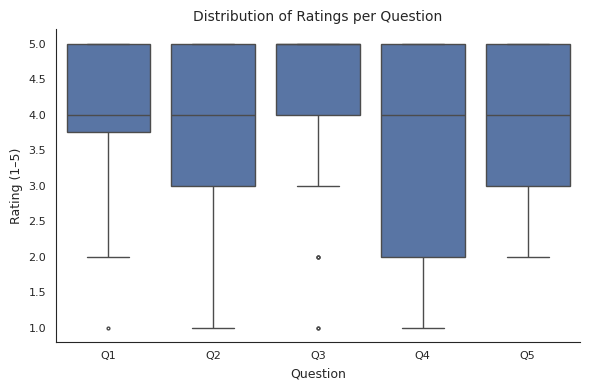

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -------------------------------------
# Aggregate readers automatically
# (No need to create combined copy — just use df)
# -------------------------------------

sns.set_style("white")

plt.figure(figsize=(6, 4))

sns.boxplot(
    data=df,
    x="Question",   # vertical orientation
    y="Rating",
    color="#4C72B0",   # nice strong blue (journal-safe)
    fliersize=2,
    linewidth=1
)

plt.title("Distribution of Ratings per Question", fontsize=10)
plt.xlabel("Question", fontsize=9)
plt.ylabel("Rating (1–5)", fontsize=9)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

sns.despine()
plt.tight_layout()

plt.savefig("Figure4_aggregated_vertical.png", dpi=300, bbox_inches="tight")
plt.show()

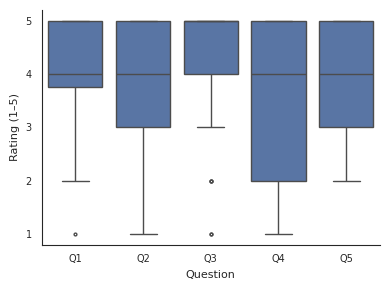

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("white")

plt.figure(figsize=(4, 3))  # reduced size

sns.boxplot(
    data=df,
    x="Question",
    y="Rating",
    color="#4C72B0",
    fliersize=2,
    linewidth=1
)

# plt.title("Distribution of Ratings per Question", fontsize=9)
plt.xlabel("Question", fontsize=8)
plt.ylabel("Rating (1–5)", fontsize=8)

plt.xticks(fontsize=7)
plt.yticks(fontsize=7)

sns.despine()
plt.tight_layout()

plt.savefig("Figure4_compact.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
# Compute mean rating per question
mean_scores = df.groupby("Question")["Rating"].mean().reset_index()

print(mean_scores)

  Question    Rating
0       Q1  4.065789
1       Q2  3.907895
2       Q3  4.302632
3       Q4  3.421053
4       Q5  3.986842


In [8]:
mean_scores = df.groupby("Question")["Rating"].mean().reset_index()

# Round to 2 decimal places
mean_scores["Mean_out_of_5"] = mean_scores["Rating"].round(2)

# Convert to percentage of 5
mean_scores["Percentage"] = (mean_scores["Rating"] / 5 * 100).round(1)

mean_scores = mean_scores.drop(columns=["Rating"])

print(mean_scores)

overall_mean = df["Rating"].mean()

print("Overall mean score: {:.2f} / 5".format(overall_mean))

  Question  Mean_out_of_5  Percentage
0       Q1           4.07        81.3
1       Q2           3.91        78.2
2       Q3           4.30        86.1
3       Q4           3.42        68.4
4       Q5           3.99        79.7
Overall mean score: 3.94 / 5


In [9]:
df.groupby("Question")["Rating"].median()

Question
Q1    4.0
Q2    4.0
Q3    5.0
Q4    4.0
Q5    4.0
Name: Rating, dtype: float64

In [10]:
print(df[df["Question"] == "Q4"]["Rating"].describe())

count    76.000000
mean      3.421053
std       1.453852
min       1.000000
25%       2.000000
50%       4.000000
75%       5.000000
max       5.000000
Name: Rating, dtype: float64


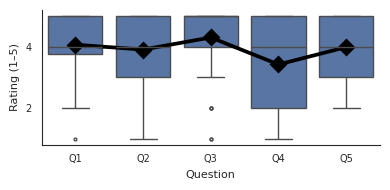

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("white")
plt.figure(figsize=(4, 3))  # reduced size

sns.boxplot(data=df, x="Question", y="Rating", color="#4C72B0", fliersize=2, linewidth=1)

# Overlay mean as black diamond
sns.pointplot(data=df, x="Question", y="Rating", color="black", markers="D", errorbar=None)

# plt.title("Ratings per Question", fontsize=9)
plt.xlabel("Question", fontsize=8)
plt.ylabel("Rating (1–5)", fontsize=8)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
sns.despine()
plt.tight_layout()
plt.savefig("Figure4_compactdiamond.png", dpi=300, bbox_inches="tight")

plt.show()

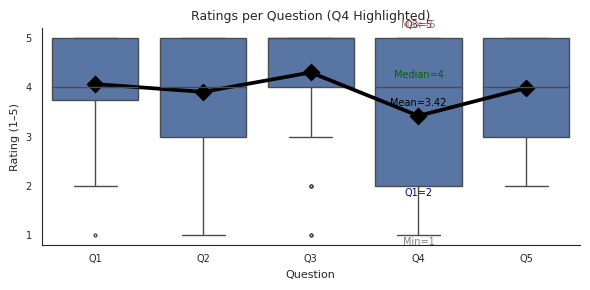

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("white")
plt.figure(figsize=(6,3))

# Base boxplot (aggregated over all readers)
ax = sns.boxplot(
    data=df,
    x="Question",
    y="Rating",
    color="#4C72B0",
    fliersize=2,
    linewidth=1
)

# Overlay mean as black diamond
sns.pointplot(
    data=df,
    x="Question",
    y="Rating",
    color="black",
    markers="D",
    errorbar=None
)

# Annotate quartiles and mean for Q4
q4_data = df[df["Question"] == "Q4"]["Rating"]
q1 = q4_data.quantile(0.25)
median = q4_data.median()
q3 = q4_data.quantile(0.75)
mean = q4_data.mean()
_min = q4_data.min()
_max = q4_data.max()

# Add text labels directly on the plot
ax.text(3, q1-0.2, f"Q1={q1:.0f}", ha="center", fontsize=7, color="darkblue")
ax.text(3, median+0.2, f"Median={median:.0f}", ha="center", fontsize=7, color="darkgreen")
ax.text(3, q3+0.2, f"Q3={q3:.0f}", ha="center", fontsize=7, color="darkred")
ax.text(3, _min-0.2, f"Min={_min}", ha="center", fontsize=7, color="gray")
ax.text(3, _max+0.2, f"Max={_max}", ha="center", fontsize=7, color="gray")
ax.text(3, mean+0.2, f"Mean={mean:.2f}", ha="center", fontsize=7, color="black")

# Labels
plt.title("Ratings per Question (Q4 Highlighted)", fontsize=9)
plt.xlabel("Question", fontsize=8)
plt.ylabel("Rating (1–5)", fontsize=8)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)

sns.despine()
plt.tight_layout()
plt.show()

In [1]:
import requests

url = "https://zenodo.org/records/5037046/files/testslide.isyntax?download=1"
filename = "testslide.isyntax"

response = requests.get(url)
with open(filename, "wb") as f:
    f.write(response.content)

print(f"Downloaded file as {filename}")

Downloaded file as testslide.isyntax


In [2]:
import math
import numpy as np
from isyntax import ISyntax
from pydicom.dataset import Dataset, FileDataset
from pydicom.uid import generate_uid
from pydicom.encaps import encapsulate_extended
from pydicom.sequence import Sequence
import pywt
import datetime
import os

# -----------------------------
# Configuration
# -----------------------------
ISYNTAX_FILE = "testslide.isyntax"
OUTPUT_DCM = "/HPC/fnu.talha/level0_wsi_custom.dcm"

TILE_SIZE = 1024
BACKGROUND_THRESHOLD = 245
DWT_LEVELS = 2
BATCH_SIZE = 50  # flush every 50 tiles
USE_GPU = False  # set True if CuPy & GPU available

if USE_GPU:
    import cupy as cp
    xp = cp
else:
    xp = np

# -----------------------------
# Background detection
# -----------------------------
def is_background(tile, threshold=BACKGROUND_THRESHOLD):
    return tile.mean() > threshold

# -----------------------------
# Bitplane + RLE compression
# -----------------------------
def bitplane_rle(subband, scale=255):
    max_val = np.max(np.abs(subband))
    if max_val == 0:
        return [b'\x00']

    subband_int = np.round(subband / max_val * scale).astype(np.int32)
    max_coeff = int(np.max(np.abs(subband_int)))
    if max_coeff == 0:
        return [b'\x00']

    nbits = max_coeff.bit_length()
    planes = []

    for b in reversed(range(nbits)):
        plane = ((subband_int >> b) & 1).astype(np.uint8).flatten()
        rle = []
        prev = int(plane[0])
        count = 1
        for val in plane[1:]:
            if val == prev and count < 255:
                count += 1
            else:
                rle.extend([prev, count])
                prev = int(val)
                count = 1
        rle.extend([prev, count])
        planes.append(bytes(rle))
    return planes

# -----------------------------
# Tile compression
# -----------------------------
def compress_tile(tile):
    all_bytes = []
    for c in range(3):
        channel = tile[..., c]
        coeffs = pywt.wavedec2(channel, 'haar', level=DWT_LEVELS)
        for level in coeffs:
            if isinstance(level, tuple):
                for sub in level:
                    all_bytes.extend(bitplane_rle(sub))
            else:
                all_bytes.extend(bitplane_rle(level))
    return b''.join(all_bytes)

# -----------------------------
# Initialize DICOM
# -----------------------------
file_meta = Dataset()
file_meta.MediaStorageSOPClassUID = "1.2.840.10008.5.1.4.1.1.77.1.6"
file_meta.MediaStorageSOPInstanceUID = generate_uid()
file_meta.TransferSyntaxUID = "1.2.840.10008.1.2.4.90"
file_meta.ImplementationClassUID = generate_uid()

ds = FileDataset(OUTPUT_DCM, {}, file_meta=file_meta, preamble=b"\0"*128)
ds.SOPClassUID = file_meta.MediaStorageSOPClassUID
ds.SOPInstanceUID = file_meta.MediaStorageSOPInstanceUID
ds.StudyInstanceUID = generate_uid()
ds.SeriesInstanceUID = generate_uid()
ds.Modality = "SM"
ds.Rows = TILE_SIZE
ds.Columns = TILE_SIZE
ds.SamplesPerPixel = 3
ds.PhotometricInterpretation = "RGB"
ds.BitsAllocated = 8
ds.BitsStored = 8
ds.HighBit = 7

frames = []
positions = []
frame_count = 0

# -----------------------------
# Process slide in batches
# -----------------------------
with ISyntax.open(ISYNTAX_FILE) as isy:
    full_width, full_height = isy.level_dimensions[0]
    ds.TotalPixelMatrixRows = full_height
    ds.TotalPixelMatrixColumns = full_width

    tiles_x = math.ceil(full_width / TILE_SIZE)
    tiles_y = math.ceil(full_height / TILE_SIZE)

    for ty in range(tiles_y):
        for tx in range(tiles_x):
            x0 = tx * TILE_SIZE
            y0 = ty * TILE_SIZE
            w = min(TILE_SIZE, full_width - x0)
            h = min(TILE_SIZE, full_height - y0)

            tile = np.array(isy.read_region(x0, y0, w, h, 0))[..., :3]

            if tile.shape[0] != TILE_SIZE or tile.shape[1] != TILE_SIZE:
                pad = ((0, TILE_SIZE - tile.shape[0]),
                       (0, TILE_SIZE - tile.shape[1]),
                       (0, 0))
                tile = np.pad(tile, pad, mode='constant')

            # compress tile
            if is_background(tile):
                compressed = b'\x00' * 50
            else:
                compressed = compress_tile(tile)

            frames.append(compressed)
            positions.append((x0, y0))
            frame_count += 1

            # Flush batch to DICOM
            if len(frames) >= BATCH_SIZE:
                if "PixelData" not in ds:
                    ds.PixelData = encapsulate_extended(frames)
                else:
                    ds.PixelData += encapsulate_extended(frames)
                frames.clear()

            del tile
            del compressed

            if frame_count % 100 == 0:
                print("Tiles processed:", frame_count)

# Flush remaining frames
if frames:
    if "PixelData" not in ds:
        ds.PixelData = encapsulate_extended(frames)
    else:
        ds.PixelData += encapsulate_extended(frames)
    frames.clear()

# -----------------------------
# Save DICOM
# -----------------------------
ds.NumberOfFrames = frame_count
ds["PixelData"].is_undefined_length = True
ds.save_as(OUTPUT_DCM)

print("DICOM saved:", OUTPUT_DCM)
print("Total frames:", frame_count)

KeyboardInterrupt: 

In [1]:
import math
import numpy as np
from isyntax import ISyntax
from pydicom.dataset import Dataset, FileDataset
from pydicom.uid import generate_uid
from pydicom.encaps import encapsulate_extended
from pydicom.sequence import Sequence
import pywt
import datetime
import os

# -----------------------------
# Configuration
# -----------------------------
ISYNTAX_FILE = "testslide.isyntax"
OUTPUT_DCM = "/HPC/fnu.talha/level0_wsi_custom.dcm"

TILE_SIZE = 1024
BACKGROUND_THRESHOLD = 245
DWT_LEVELS = 2
BATCH_SIZE = 50  # flush every 50 tiles
USE_GPU = False  # set True if CuPy & GPU available

if USE_GPU:
    import cupy as cp
    xp = cp
else:
    xp = np

# -----------------------------
# Background detection
# -----------------------------
def is_background(tile, threshold=BACKGROUND_THRESHOLD):
    return tile.mean() > threshold

# -----------------------------
# Bitplane + RLE compression
# -----------------------------
def bitplane_rle(subband, scale=255):
    max_val = np.max(np.abs(subband))
    if max_val == 0:
        return [b'\x00']

    subband_int = np.round(subband / max_val * scale).astype(np.int32)
    max_coeff = int(np.max(np.abs(subband_int)))
    if max_coeff == 0:
        return [b'\x00']

    nbits = max_coeff.bit_length()
    planes = []

    for b in reversed(range(nbits)):
        plane = ((subband_int >> b) & 1).astype(np.uint8).flatten()
        rle = []
        prev = int(plane[0])
        count = 1
        for val in plane[1:]:
            if val == prev and count < 255:
                count += 1
            else:
                rle.extend([prev, count])
                prev = int(val)
                count = 1
        rle.extend([prev, count])
        planes.append(bytes(rle))
    return planes

# -----------------------------
# Tile compression
# -----------------------------
def compress_tile(tile):
    all_bytes = []
    for c in range(3):
        channel = tile[..., c]
        coeffs = pywt.wavedec2(channel, 'haar', level=DWT_LEVELS)
        for level in coeffs:
            if isinstance(level, tuple):
                for sub in level:
                    all_bytes.extend(bitplane_rle(sub))
            else:
                all_bytes.extend(bitplane_rle(level))
    return b''.join(all_bytes)

# -----------------------------
# Initialize DICOM
# -----------------------------
file_meta = Dataset()
file_meta.MediaStorageSOPClassUID = "1.2.840.10008.5.1.4.1.1.77.1.6"
file_meta.MediaStorageSOPInstanceUID = generate_uid()
file_meta.TransferSyntaxUID = "1.2.840.10008.1.2.4.90"
file_meta.ImplementationClassUID = generate_uid()

ds = FileDataset(OUTPUT_DCM, {}, file_meta=file_meta, preamble=b"\0"*128)
ds.SOPClassUID = file_meta.MediaStorageSOPClassUID
ds.SOPInstanceUID = file_meta.MediaStorageSOPInstanceUID
ds.StudyInstanceUID = generate_uid()
ds.SeriesInstanceUID = generate_uid()
ds.Modality = "SM"
ds.Rows = TILE_SIZE
ds.Columns = TILE_SIZE
ds.SamplesPerPixel = 3
ds.PhotometricInterpretation = "RGB"
ds.BitsAllocated = 8
ds.BitsStored = 8
ds.HighBit = 7

frames = []
positions = []
frame_count = 0

# -----------------------------
# Process slide in batches
# -----------------------------
with ISyntax.open(ISYNTAX_FILE) as isy:
    full_width, full_height = isy.level_dimensions[0]
    ds.TotalPixelMatrixRows = full_height
    ds.TotalPixelMatrixColumns = full_width

    tiles_x = math.ceil(full_width / TILE_SIZE)
    tiles_y = math.ceil(full_height / TILE_SIZE)

    for ty in range(tiles_y):
        for tx in range(tiles_x):
            x0 = tx * TILE_SIZE
            y0 = ty * TILE_SIZE
            w = min(TILE_SIZE, full_width - x0)
            h = min(TILE_SIZE, full_height - y0)

            tile = np.array(isy.read_region(x0, y0, w, h, 0))[..., :3]

            if tile.shape[0] != TILE_SIZE or tile.shape[1] != TILE_SIZE:
                pad = ((0, TILE_SIZE - tile.shape[0]),
                       (0, TILE_SIZE - tile.shape[1]),
                       (0, 0))
                tile = np.pad(tile, pad, mode='constant')

            # compress tile
            if is_background(tile):
                compressed = b'\x00' * 50
            else:
                compressed = compress_tile(tile)

            frames.append(compressed)
            positions.append((x0, y0))
            frame_count += 1

            # Flush batch to DICOM
            if len(frames) >= BATCH_SIZE:
                if "PixelData" not in ds:
                    ds.PixelData = encapsulate_extended(frames)
                else:
                    ds.PixelData += encapsulate_extended(frames)
                frames.clear()

            del tile
            del compressed

            if frame_count % 100 == 0:
                print("Tiles processed:", frame_count)

# Flush remaining frames
if frames:
    if "PixelData" not in ds:
        ds.PixelData = encapsulate_extended(frames)
    else:
        ds.PixelData += encapsulate_extended(frames)
    frames.clear()

# -----------------------------
# Save DICOM
# -----------------------------
ds.NumberOfFrames = frame_count
ds["PixelData"].is_undefined_length = True
ds.save_as(OUTPUT_DCM)

print("DICOM saved:", OUTPUT_DCM)
print("Total frames:", frame_count)

Tiles processed: 100
Tiles processed: 200
Tiles processed: 300
Tiles processed: 400
Tiles processed: 500


KeyboardInterrupt: 

In [4]:
import math
import numpy as np
from isyntax import ISyntax
from pydicom.dataset import Dataset, FileDataset
from pydicom.uid import generate_uid, JPEG2000
from pydicom.encaps import encapsulate_extended
import pywt
import zstandard as zstd
from joblib import Parallel, delayed
import os

# -------------------------
# Config
# -------------------------
ISYNTAX_FILE = "/tmp/testslide.isyntax"
OUTPUT_DCM = "/HPC/fnu.talha/level0_wsi_compressed.dcm"

TILE_SIZE = 1024
BACKGROUND_THRESHOLD = 245
DWT_LEVELS = 4
MAX_WORKERS = int(os.environ.get("SLURM_CPUS_PER_TASK", 16))

# Quantization step sizes for subbands (can tweak for higher compression)
QUANTIZATION = {
    'LL': 4,
    'LH': 12,
    'HL': 12,
    'HH': 24
}

# -------------------------
# Helper functions
# -------------------------

def is_background(tile):
    return tile.mean() > BACKGROUND_THRESHOLD

def rgb_to_ycbcr(tile):
    """Convert tile to YCbCr and downsample chroma (4:2:0)"""
    r, g, b = tile[...,0], tile[...,1], tile[...,2]
    y  = 0.299*r + 0.587*g + 0.114*b
    cb = -0.1687*r - 0.3313*g + 0.5*b + 128
    cr = 0.5*r - 0.4187*g - 0.0813*b + 128
    # Chroma subsample 4:2:0
    cb = cb[::2, ::2]
    cr = cr[::2, ::2]
    return y, cb, cr

def quantize(coeff, q):
    return np.round(coeff / q).astype(np.int16)


# quantization dictionary
QUANTIZATION = {
    'LL': 4,
    'LH': 12,
    'HL': 12,
    'HH': 24
}

def compress_channel(channel):
    """
    Compress a single channel using wavelet + quantization + zstd.
    Robust to variable number of subbands and small tiles.
    """
    coeffs = pywt.wavedec2(channel, 'haar', level=4)
    all_bytes = []

    # LL band
    LL = coeffs[0]
    qLL = np.round(LL / QUANTIZATION['LL']).astype(np.int16)
    all_bytes.append(zstd.compress(qLL.tobytes(), level=12))

    # All other levels
    subband_names = ['LH', 'HL', 'HH']
    for level_idx, band in enumerate(coeffs[1:], start=1):
        if not isinstance(band, tuple):
            # safety fallback if unexpected
            band = (band,)

        for j, sub in enumerate(band):
            # fallback: if more subbands than names, use 'HH'
            name = subband_names[j] if j < len(subband_names) else 'HH'
            q = np.round(sub / QUANTIZATION.get(name, 24)).astype(np.int16)
            all_bytes.append(zstd.compress(q.tobytes(), level=12))

    return b''.join(all_bytes)

def compress_tile(tile):
    if is_background(tile):
        return None  # skip background tiles
    y, cb, cr = rgb_to_ycbcr(tile)
    return compress_channel(y) + compress_channel(cb) + compress_channel(cr)

# -------------------------
# Process WSI
# -------------------------

frames = []
frame_count = 0

with ISyntax.open(ISYNTAX_FILE) as isy:
    full_width, full_height = isy.level_dimensions[0]
    tiles_x = math.ceil(full_width / TILE_SIZE)
    tiles_y = math.ceil(full_height / TILE_SIZE)

    batch_tiles = []

    for ty in range(tiles_y):
        for tx in range(tiles_x):
            x0 = tx * TILE_SIZE
            y0 = ty * TILE_SIZE
            w = min(TILE_SIZE, full_width - x0)
            h = min(TILE_SIZE, full_height - y0)

            tile = np.array(isy.read_region(x0, y0, w, h, 0))[..., :3]

            if tile.shape[0] != TILE_SIZE or tile.shape[1] != TILE_SIZE:
                pad = ((0, TILE_SIZE - tile.shape[0]),
                       (0, TILE_SIZE - tile.shape[1]),
                       (0, 0))
                tile = np.pad(tile, pad)

            batch_tiles.append(tile)

            if len(batch_tiles) == MAX_WORKERS:
                compressed = Parallel(n_jobs=MAX_WORKERS)(
                    delayed(compress_tile)(t) for t in batch_tiles
                )
                # filter out None (background tiles)
                compressed = [f for f in compressed if f is not None]
                frames.extend(compressed)
                frame_count += len(compressed)
                batch_tiles = []

    # last batch
    if batch_tiles:
        compressed = Parallel(n_jobs=MAX_WORKERS)(
            delayed(compress_tile)(t) for t in batch_tiles
        )
        compressed = [f for f in compressed if f is not None]
        frames.extend(compressed)
        frame_count += len(compressed)

# -------------------------
# DICOM writing
# -------------------------

file_meta = Dataset()
file_meta.MediaStorageSOPClassUID = "1.2.840.10008.5.1.4.1.1.77.1.6"
file_meta.MediaStorageSOPInstanceUID = generate_uid()
file_meta.TransferSyntaxUID = JPEG2000  # declared transfer syntax
file_meta.ImplementationClassUID = generate_uid()

ds = FileDataset(OUTPUT_DCM, {}, file_meta=file_meta, preamble=b"\0"*128)
ds.Rows = TILE_SIZE
ds.Columns = TILE_SIZE
ds.SamplesPerPixel = 3
ds.PhotometricInterpretation = "RGB"
ds.BitsAllocated = 8
ds.BitsStored = 8
ds.HighBit = 7
ds.TotalPixelMatrixRows = full_height
ds.TotalPixelMatrixColumns = full_width
ds.NumberOfFrames = frame_count

# encapsulate frames
encapsulated, offsets, lengths = encapsulate_extended(frames)
ds.PixelData = encapsulated
ds.ExtendedOffsetTable = offsets
ds.ExtendedOffsetTableLengths = lengths
ds["PixelData"].is_undefined_length = True

ds.save_as(OUTPUT_DCM)
print(f"DICOM saved: {OUTPUT_DCM} with {frame_count} frames")

DICOM saved: /HPC/fnu.talha/level0_wsi_compressed.dcm with 2664 frames


In [11]:
encapsulated, offsets, lengths = encapsulate_extended(frames)

ds.PixelData = encapsulated
ds.ExtendedOffsetTable = offsets
ds.NumberOfFrames = frame_count
ds["PixelData"].is_undefined_length = True

ds.save_as(OUTPUT_DCM)

print("DICOM saved")

DICOM saved


In [1]:
print(len(frames[0]))

NameError: name 'frames' is not defined

In [5]:
cp testslide.isyntax /tmp/